# Classwork 5

The goals of this assignment are to help you (1) calculate expectations of random variables using R, (2) simulate probabilistic processes, and (3) estimate probabilities and other quantities through numerical (computer) simulation. Such simulations can be useful. We can use simulations to help confirm that we've calculated a probability "by hand" correctly, or to estimate other quantities, like areas/integrals!

## Problem #1

**1.(a) Write a function to calculate the expected value of a binomial random variable, using the definition of expectation. In other words, if $X \sim \text{Bin}(n, p)$, your function should take $n$ and $p$ as inputs, and return $E[X]$.**



In [1]:
# 1) CODE HERE

binom_exp = function(n, p) {
    x <- 0:n
    expectation <- sum(x * dbinom(x, n, p))
    return (expectation)
}

binom_exp(100, 1/4)

[1] 25

**1.(b) Store $m = 10,000$ binomial random numbers in a vector `x`. Each entry of `x` should represent the number of heads in $50$ flips of a biased coin (where $P(\text{Heads}) = 0.75$).**

In [2]:
# 2) CODE HERE
set.seed(37)
n <- 50
p <- 0.75
m <- 10000
x <- rbinom(m, size = n, prob = p)
head(x)

[1] 37 42 36 38 36 34

**(c) Calculate the (sample) mean of `x`. Then, use the formula for the mean of a binomial, and the function above, to calculuate the mean of the random variable $X$, where $X$ counts the number of tails in 50 flips of a biased coin (again, $P(\text{Heads}) = 0.75$). What do you notice? Do these answers match?**

In [3]:
# 3) CODE HERE
paste0("The sample mean of the vector x is ", mean(x), ".")

paste0("the formula for the expected value of a binomial random variable",
       " implies E[X]=", n * (p), ".")

paste0("The function above calculates that the expected value of X is ",
      binom_exp(n=n, p=p))

[1] "The sample mean of the vector x is 37.5097."

[1] "the formula for the expected value of a binomial random variable implies E[X]=37.5."

[1] "The function above calculates that the expected value of X is 37.5"

The formula $E[X] = n \cdot p$ and the function `bin_exp()` both yield the same value, since the latter can compute this value very accurately given that $X$ is a discrete random variable. However, the sample mean is slightly different, since it comes from a random sampling of $X$.

## Problem #2 

**2.(a) First, write a function to calculate the expected value of an exponential random variable for an arbitrary $\lambda$. Then, use it to compute the expected value $E[X]$, where $X \sim \text{Exp}(1/4)$. Hint: first make a function `integrand()` which takes a vector `x` and `lambda` as arguments, and then pass it to the `integrate()` function in `R`.**

In [4]:
# 4) CODE HERE

integrand <- function(x, lambda) {
    fx = x * dexp(x, lambda)
    return(fx)
}
exp_exp <- function(l) {
    I <- integrate(integrand,
                   lower = 0,
upper = Inf, lambda=l)
return(I) }
exp_exp(1 / 4)

4 with absolute error < 1.2e-05

**2.(b) Consider the PDF $f(x) = \frac{3}{2}(1-x^2)$ on $0 \le x \le 1$ (zero elsewhere). Suppose that $f(x)$ is the PDF for a random variable $X$. Find $E[X^3]$.** (*Note*: you may do this in `R` using the integrate function, or by hand).

In [3]:
# 5) CODE HERE

f = function(x) {
    f = x^3*(3/2)*(1-x^2)
    return(f)
}

integrate(f, 0,1)

0.125 with absolute error < 1.4e-15

**2.(c) Estimate $E[X^3]$ using Monte Carlo integration. How could you get a better estimate?**

In [4]:
# 6) CODE HERE
m=50000
x = runif(m,0,1)
y = runif(m,0,1)

below = sum(y<f(x))
print(below)

[1] 6229


## Problem #3

In class, we emphasized that variables can be uncorrelated but dependent. Let's look at an example of this.

**3.(a) Generate $n = 5000$ random variables from a $\text{Unif}(-1,1)$ distribution. Store these values in `x`. Then, create a variable `y` such that $y = x^2$. Plot `x` and `y` and compute the (sample) correlation coefficient using `cor()`. What do you notice?**

[1] -0.02626776

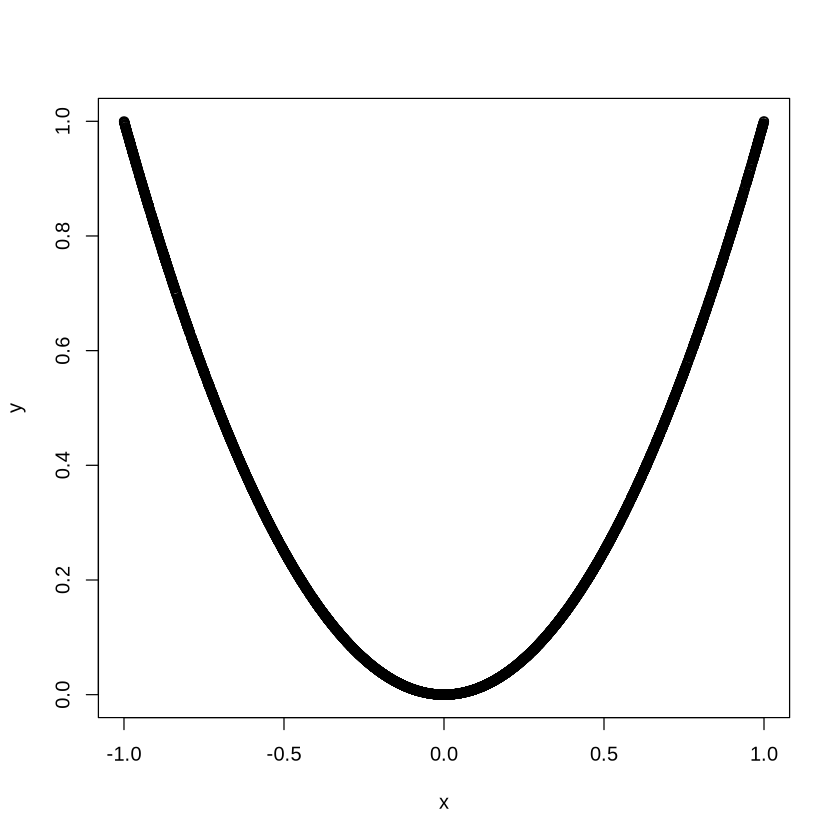

In [5]:
# 7) CODE HERE
n=5000
x=runif(n, -1, 1)
y=x^2
plot(x,y)

cor(x,y)

**3.(b) Now add various degrees of "noise" to `y`, by adding random normal numbers to the `y` equation. Use `rnorm(n,0,b)`, where `b` is set to values like `0.01`, `0.1`, and `1`. What do you notice about the plot and corresponding correlation coefficient?**

In [ ]:
# 8) CODE HERE

[1] -0.02655385

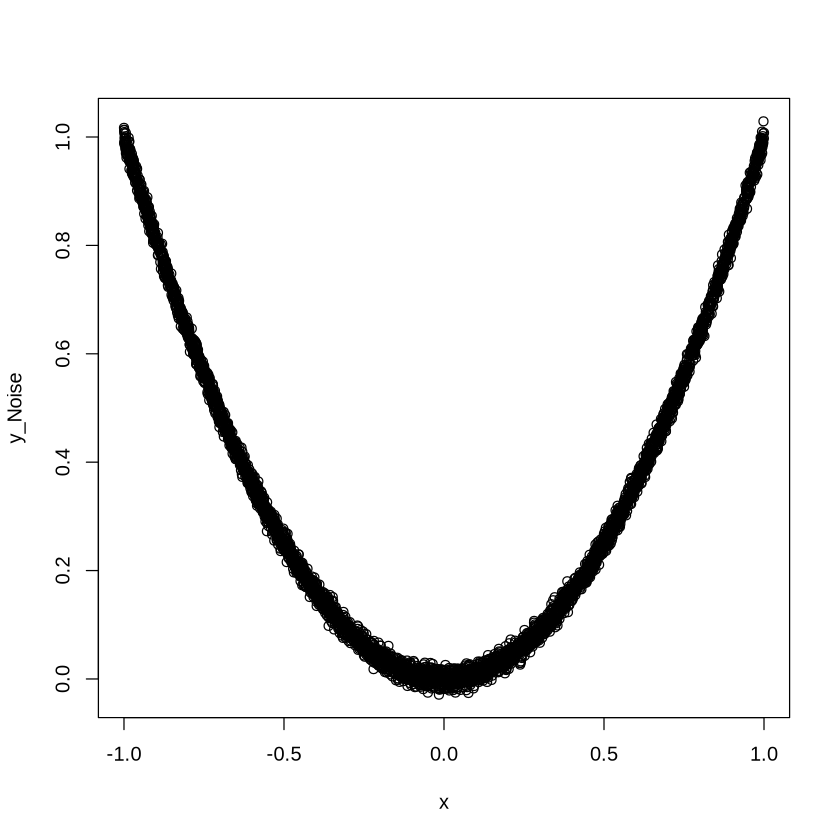

In [11]:
b=c(0.01, 0.1, 1)
y_Noise = x^2 + rnorm(n, 0, b[1])
plot(x, y_Noise)
cor(x, y_Noise)

[1] -0.02266164

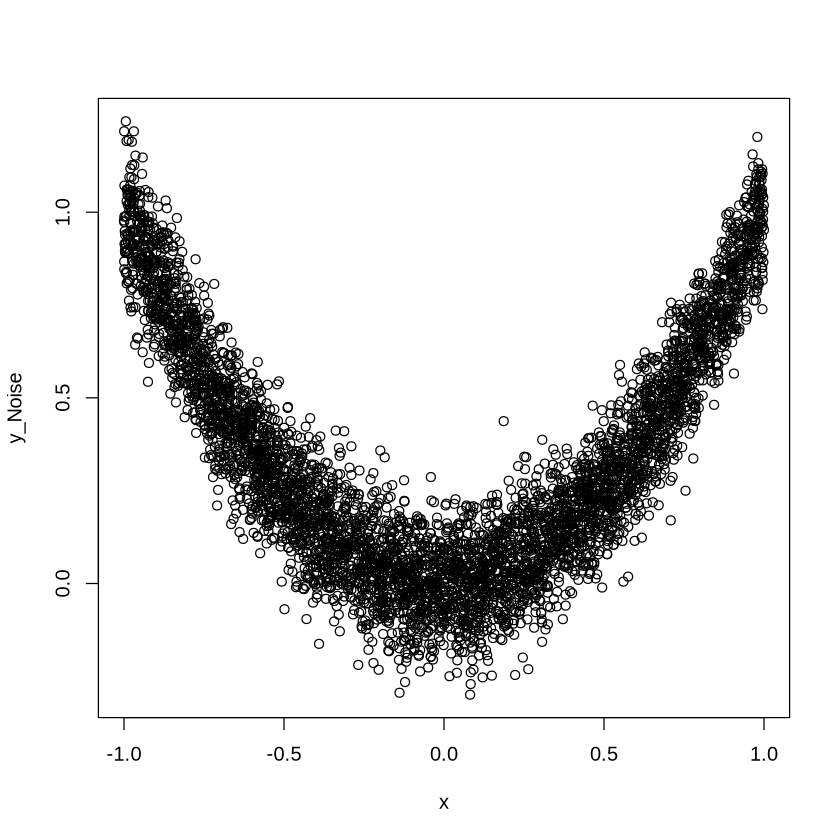

In [12]:
y_Noise = x^2 + rnorm(n, 0, b[2])
plot(x, y_Noise)
cor(x,y_Noise)

[1] -0.02642718

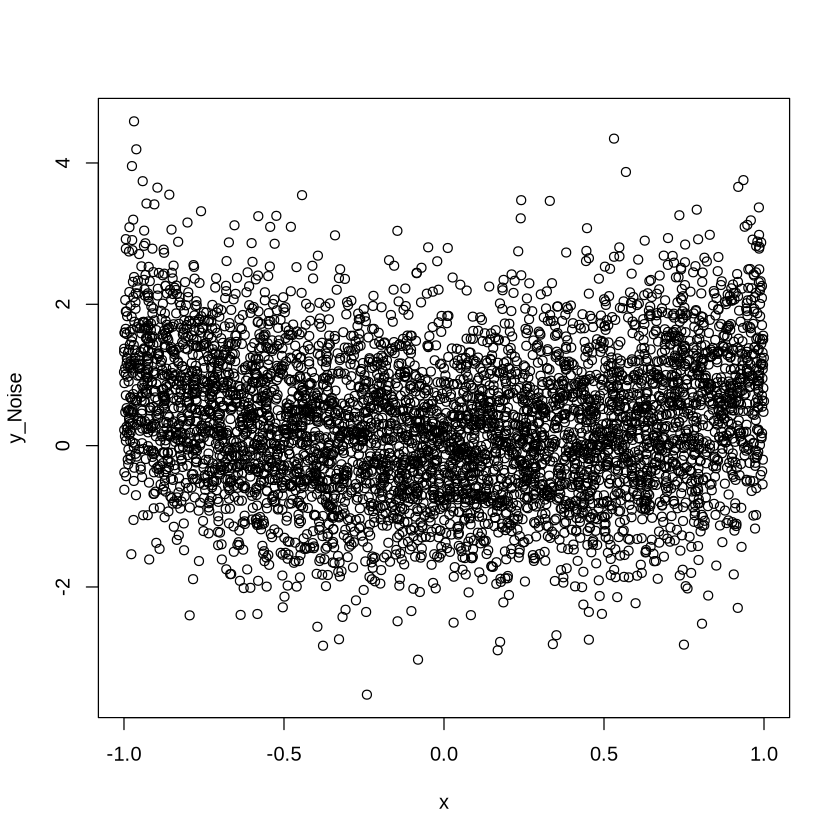

In [10]:
y_Noise = x^2 + rnorm(n, 0, b[3])
plot(x, y_Noise)
cor(x,y_Noise)

THe relationship btw noise and correlation was less defined as the noise increases. the correlation is not high for any of them, and correlation coefficient decreased in magnitude, but not significantly.